# Análisis exploratorio de reingresos hospitalarios a 30 días
**Proyecto de aula de Inteligencia Artificial · Fase 1 · Grupo 04**  
**Michel Custodes · Iván Güette · Maira Torres**  
Ingeniería de Sistemas · Séptimo semestre · Valledupar, Cesar · 2026

Este notebook describe el conjunto público de hospitalizaciones con diagnóstico de diabetes y documenta su calidad antes del modelado. La unidad de análisis es la hospitalización; una misma persona puede aparecer en varios encuentros.

El análisis se organiza en cinco partes: carga e integridad de archivos, volumetría inicial, diccionario de variables, calidad de datos y distribución de la variable objetivo. Las estadísticas descriptivas se incluyen en la segunda parte; los valores atípicos, en la cuarta. Se examina la **base original completa**, sin excluir registros, imputar valores ni entrenar modelos.

**Uso.** Abre el archivo en Jupyter o cárgalo en Google Colab y ejecuta todas las celdas en orden. Con Internet, se descargan los dos CSV oficiales de UCI. Sin conexión, colócalos en la carpeta `data` junto al notebook; también se aceptan en la carpeta de ejecución. Las salidas están incorporadas y se regeneran en `resultados_eda_fase1`.

Se requieren Python 3, pandas, NumPy y Matplotlib. El entorno de esta entrega utiliza Python 3.12, pandas 2.2.3, NumPy 2.3.5 y Matplotlib 3.10.8. Si falta alguna biblioteca, puede instalarse en una celda adicional:

```python
%pip install pandas==2.2.3 numpy==2.3.5 matplotlib==3.10.8
```

## 1 Carga e integridad de archivos

Se utiliza **Diabetes 130-US Hospitals for Years 1999–2008**, publicado por Clore, Cios, DeShazo y Strack (2014) en UCI, con licencia **CC BY 4.0**.

- [Página oficial y descripción](https://archive.ics.uci.edu/dataset/296/diabetes+130+us+hospitals+for+years+1999+2008)
- [Descarga directa del ZIP](https://archive.ics.uci.edu/static/public/296/diabetes%2B130-us%2Bhospitals%2Bfor%2Byears%2B1999-2008.zip)
- [Identificador permanente del dataset](https://doi.org/10.24432/C5230J)

`diabetic_data.csv` contiene las hospitalizaciones. `IDS_mapping.csv` explica códigos administrativos de ingreso y egreso. El conjunto refleja registros de Estados Unidos; no contiene RIPS ni datos de hospitales colombianos.

La lectura conserva la cadena `None` en los resultados de laboratorio, donde indica una prueba no realizada. Solo `?` y cadenas vacías se interpretan como ausencias. Los diagnósticos se leen como texto para no perder códigos alfanuméricos. Las huellas SHA-256 permiten identificar exactamente los archivos empleados.

In [1]:
%matplotlib inline
from pathlib import Path
from urllib.request import urlopen
import io, zipfile, hashlib, json, platform, csv, shutil
from datetime import datetime, timezone
from IPython.display import display, Markdown
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA = Path('data')
OUT = Path('resultados_eda_fase1')
DATA.mkdir(exist_ok=True)
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titlesize': 12})
print('Python:', platform.python_version())
print('pandas:', pd.__version__, '| NumPy:', np.__version__, '| Matplotlib:', __import__('matplotlib').__version__)
pd.set_option('display.max_rows', 60)
pd.set_option('display.max_columns', 12)
pd.set_option('display.precision', 3)
def mostrar(tabla, decimales=3):
    """Muestra tablas legibles sin modificar los datos originales."""
    with pd.option_context('display.max_colwidth', 110):
        display(tabla.round(decimales))
def es_num(n, decimales=0):
    return f'{n:,.{decimales}f}'.replace(',', 'X').replace('.', ',').replace('X', '.')
ejecutado_utc = datetime.now(timezone.utc).isoformat(timespec='seconds')
print('Fecha de ejecución UTC:', ejecutado_utc)

No event loop hook running.
Python: 3.12.14
pandas: 2.2.3 | NumPy: 2.3.5 | Matplotlib: 3.10.8
Fecha de ejecución UTC: 2026-09-24T20:10:19+00:00


In [2]:
URL = 'https://archive.ics.uci.edu/static/public/296/diabetes%2B130-us%2Bhospitals%2Bfor%2Byears%2B1999-2008.zip'
archivos = ['diabetic_data.csv', 'IDS_mapping.csv']
esperadas = {
    'diabetic_data.csv': '0689e7ec031237dc63031b938805c48377748761a3b26acab621567afa24df97',
    'IDS_mapping.csv': 'f1bb82b471cb34649352597572c9b1fb00bd27f77b9f5a22a03dc3eb1039749e'
}
# Admitir los CSV cargados directamente en Jupyter o Colab.
for nombre in archivos:
    if not (DATA/nombre).exists() and Path(nombre).exists():
        shutil.copyfile(Path(nombre), DATA/nombre)
faltan = [nombre for nombre in archivos if not (DATA/nombre).exists()]
if faltan:
    try:
        with urlopen(URL, timeout=90) as respuesta:
            contenido_zip = respuesta.read()
        with zipfile.ZipFile(io.BytesIO(contenido_zip)) as archivo_zip:
            for nombre in faltan:
                (DATA/nombre).write_bytes(archivo_zip.read(nombre))
    except Exception as error:
        raise RuntimeError('No fue posible completar la descarga. Descarga el ZIP oficial, '
                           'extrae ambos CSV y colócalos en data; luego ejecuta de nuevo.') from error
huellas = {nombre: hashlib.sha256((DATA/nombre).read_bytes()).hexdigest()
           for nombre in archivos}
for nombre in archivos:
    assert huellas[nombre] == esperadas[nombre], (
        f'{nombre} difiere del original analizado. Usa el CSV sin guardarlo de nuevo desde Excel.')
fingerprint = huellas['diabetic_data.csv']
raw = pd.read_csv(DATA/'diabetic_data.csv', keep_default_na=False,
                  na_values=['?', ''], low_memory=False,
                  dtype={'diag_1':'string', 'diag_2':'string', 'diag_3':'string',
                         'payer_code':'string'})
assert raw.shape == (101766, 50)
assert set(raw.readmitted.unique()) == {'NO', '>30', '<30'}
mostrar(pd.DataFrame({'archivo': archivos, 'SHA-256': [huellas[n] for n in archivos]}))
print('Integridad comprobada: ambas huellas coinciden con los archivos originales.')

Integridad comprobada: ambas huellas coinciden con los archivos originales.


,archivo,SHA-256
0,diabetic_data.csv,0689e7ec031237dc63031b938805c48377748761a3b26acab621567afa24df97
1,IDS_mapping.csv,f1bb82b471cb34649352597572c9b1fb00bd27f77b9f5a22a03dc3eb1039749e


## 2 Volumetría inicial

Se cuenta el número de filas, columnas y pacientes distintos. La volumetría se calcula sobre el archivo original, sin depuración ni exclusiones. Las medidas descriptivas permiten contextualizar sus variables cuantitativas.

In [3]:
volumetria = pd.DataFrame({
    'indicador': ['Hospitalizaciones o filas', 'Columnas', 'Pacientes únicos'],
    'cantidad': [len(raw), raw.shape[1], raw.patient_nbr.nunique()]
})
mostrar(volumetria)
assert len(raw) == 101766 and raw.shape[1] == 50 and raw.patient_nbr.nunique() == 71518
volumetria.to_csv(OUT/'volumetria_inicial.csv',index=False)

,indicador,cantidad
0,Hospitalizaciones o filas,101766
1,Columnas,50
2,Pacientes únicos,71518


In [4]:
# Vista compacta de variables clínicas y de utilización de servicios.
vista = ['age', 'gender', 'time_in_hospital', 'num_lab_procedures',
         'num_medications', 'number_inpatient', 'A1Cresult', 'readmitted']
mostrar(raw[vista].head(8))

,age,gender,time_in_hospital,num_lab_procedures,num_medications,number_inpatient,A1Cresult,readmitted
0,[0-10),Female,1,41,1,0,None,NO
1,[10-20),Female,3,59,18,0,None,>30
2,[20-30),Female,2,11,13,1,None,NO
3,[30-40),Male,2,44,16,0,None,NO
4,[40-50),Male,1,51,8,0,None,NO
5,[50-60),Male,3,31,16,0,None,>30
6,[60-70),Male,4,70,21,0,None,NO
7,[70-80),Male,5,73,12,0,None,>30


**Lectura de la estructura.** El archivo tiene 50 columnas: 2 identificadores, 1 desenlace y 47 características originales. El número de filas no equivale al número de pacientes. Los intervalos de `age` representan grupos de edad, no edades exactas.

### Estadísticas descriptivas de las variables cuantitativas

Se presentan conteo, media, desviación estándar, mínimo, cuartiles y máximo. Los identificadores y los códigos administrativos se excluyen de estas medidas porque sus números no representan magnitudes.

In [5]:
numeric = ['time_in_hospital','num_lab_procedures','num_procedures','num_medications',
           'number_outpatient','number_emergency','number_inpatient','number_diagnoses']
descriptive = raw[numeric].describe().T
mostrar(descriptive, 2)
descriptive.to_csv(OUT/'descriptivos_base_original.csv')

,count,mean,std,min,25%,50%,75%,max
time_in_hospital,101766.0,4.40,2.99,1.0,2.0,4.0,6.0,14.0
num_lab_procedures,101766.0,43.10,19.67,1.0,31.0,44.0,57.0,132.0
num_procedures,101766.0,1.34,1.71,0.0,0.0,1.0,2.0,6.0
num_medications,101766.0,16.02,8.13,1.0,10.0,15.0,20.0,81.0
number_outpatient,101766.0,0.37,1.27,0.0,0.0,0.0,0.0,42.0
number_emergency,101766.0,0.20,0.93,0.0,0.0,0.0,0.0,76.0
number_inpatient,101766.0,0.64,1.26,0.0,0.0,0.0,1.0,21.0
number_diagnoses,101766.0,7.42,1.93,1.0,6.0,8.0,9.0,16.0


In [6]:
display(Markdown(
    f"**Interpretación.** La estancia media es **{es_num(raw.time_in_hospital.mean(),2)} días**, "
    f"con mediana de **{es_num(raw.time_in_hospital.median())} días**. La mitad central se ubica "
    f"entre {es_num(raw.time_in_hospital.quantile(.25))} y {es_num(raw.time_in_hospital.quantile(.75))} días. "
    f"El máximo de medicamentos registrados es {es_num(raw.num_medications.max())} y el de "
    f"hospitalizaciones previas es {es_num(raw.number_inpatient.max())}. Estos máximos requieren "
    "revisión contextual; por sí solos no prueban un error de registro."))

**Interpretación.** La estancia media es **4,40 días**, con mediana de **4 días**. La mitad central se ubica entre 2 y 6 días. El máximo de medicamentos registrados es 81 y el de hospitalizaciones previas es 21. Estos máximos requieren revisión contextual; por sí solos no prueban un error de registro.

## 3 Diccionario de variables

El diccionario diferencia el tipo que detecta Python del significado de cada variable. Por ejemplo, un código administrativo puede almacenarse como entero y seguir siendo una categoría. Los identificadores permiten auditar registros y separar pacientes; se excluyen de los predictores.

**Descripción adaptativa de tratamientos.** El diccionario muestra los valores que realmente aparecen en cada columna. Se distinguen tres situaciones: ausencia total de observaciones, un único valor observado y varios valores observados. Los nulos se cuentan por separado, de modo que no se confunda una primera fila vacía con el valor constante.

Los estados posibles del esquema original son `No` —medicamento no registrado—, `Steady` —dosis estable—, `Up` —aumento— y `Down` —disminución—. Cada variable puede contener solo una parte de esas categorías.

In [7]:
descripciones = {
 'encounter_id': ('Identificación', 'Identificador del encuentro hospitalario.'),
 'patient_nbr': ('Identificación', 'Identificador del paciente para agrupar sus encuentros.'),
 'race': ('Demografía', 'Categoría racial registrada; se reserva para análisis por subgrupos.'),
 'gender': ('Demografía', 'Género registrado, incluida categoría desconocida o inválida.'),
 'age': ('Demografía', 'Intervalo de edad de diez años.'),
 'weight': ('Demografía', 'Intervalo de peso registrado en libras.'),
 'admission_type_id': ('Administración', 'Código del tipo de ingreso; ver IDS_mapping.csv.'),
 'discharge_disposition_id': ('Administración', 'Código de disposición al egreso; ver IDS_mapping.csv.'),
 'admission_source_id': ('Administración', 'Código de procedencia del ingreso; ver IDS_mapping.csv.'),
 'payer_code': ('Administración', 'Categoría del pagador o asegurador registrado.'),
 'medical_specialty': ('Administración', 'Especialidad del médico que admite al paciente.'),
 'time_in_hospital': ('Hospitalización', 'Duración del encuentro en días.'),
 'num_lab_procedures': ('Hospitalización', 'Número de pruebas de laboratorio durante el encuentro.'),
 'num_procedures': ('Hospitalización', 'Número de procedimientos distintos de laboratorio.'),
 'num_medications': ('Hospitalización', 'Número de medicamentos genéricos distintos administrados.'),
 'number_outpatient': ('Uso previo', 'Visitas ambulatorias registradas durante el año anterior.'),
 'number_emergency': ('Uso previo', 'Visitas a urgencias registradas durante el año anterior.'),
 'number_inpatient': ('Uso previo', 'Hospitalizaciones registradas durante el año anterior.'),
 'number_diagnoses': ('Diagnósticos', 'Número de diagnósticos registrados.'),
 'diag_1': ('Diagnósticos', 'Código del diagnóstico principal, en formato ICD-9.'),
 'diag_2': ('Diagnósticos', 'Código del diagnóstico secundario, en formato ICD-9.'),
 'diag_3': ('Diagnósticos', 'Código del diagnóstico adicional, en formato ICD-9.'),
 'max_glu_serum': ('Laboratorio', 'Categoría de glucosa sérica; None significa prueba no realizada.'),
 'A1Cresult': ('Laboratorio', 'Categoría de HbA1c; None significa prueba no realizada.'),
 'change': ('Tratamiento', 'Indica cambio en la medicación para diabetes: Ch o No.'),
 'diabetesMed': ('Tratamiento', 'Indica si se prescribió medicación para diabetes: Yes o No.'),
 'readmitted': ('Resultado', 'Reingreso registrado: <30, >30 o NO.')
}
tratamientos = {
    'metformin','repaglinide','nateglinide','chlorpropamide','glimepiride',
    'acetohexamide','glipizide','glyburide','tolbutamide','pioglitazone',
    'rosiglitazone','acarbose','miglitol','troglitazone','tolazamide',
    'examide','citoglipton','insulin','glyburide-metformin','glipizide-metformin',
    'glimepiride-pioglitazone','metformin-rosiglitazone','metformin-pioglitazone'
}

def descripcion_observada(serie):
    """Describe valores observados, separando explícitamente los ausentes."""
    valores = serie.dropna().unique()
    n_vals = len(valores)
    n_nulos = int(serie.isna().sum())
    if n_vals == 0:
        texto = 'Sin valores observados; todos los registros están ausentes.'
    elif n_vals == 1:
        texto = f'Constante entre registros no ausentes. Valor observado: {valores[0]}.'
    else:
        lista = sorted(str(v) for v in valores)
        presentes = ', '.join(lista[:12])
        sufijo = f' (se muestran 12 de {n_vals} valores distintos)' if n_vals > 12 else ''
        texto = f'Valores observados: {presentes}{sufijo}.'
    if n_nulos > 0 and n_vals > 0:
        texto += f' Registros ausentes: {n_nulos}.'
    return texto

for var in raw.columns:
    if var not in descripciones:
        # Una eventual columna nueva no se clasifica automáticamente como medicamento.
        grupo = 'Tratamiento' if var in tratamientos else 'Por clasificar'
        descripciones[var] = (grupo, descripcion_observada(raw[var]))
dictionary = pd.DataFrame({
 'variable': raw.columns,
 'grupo': [descripciones[c][0] for c in raw],
 'descripcion': [descripciones[c][1] for c in raw],
 'tipo_lectura': [str(raw[c].dtype) for c in raw],
 'valores_distintos': [raw[c].nunique(dropna=True) for c in raw],
 'nulos': [int(raw[c].isna().sum()) for c in raw]
})
dictionary['rol'] = dictionary.variable.map(
    lambda c: 'objetivo' if c == 'readmitted' else
    ('identificador, no predictor' if c in ['encounter_id','patient_nbr'] else 'predictor candidato'))
mostrar(dictionary[['variable','grupo','descripcion','tipo_lectura','valores_distintos','nulos']])
dictionary.to_csv(OUT/'diccionario_variables.csv', index=False)

,variable,grupo,descripcion,tipo_lectura,valores_distintos,nulos
0,encounter_id,Identificación,Identificador del encuentro hospitalario.,int64,101766,0
1,patient_nbr,Identificación,Identificador del paciente para agrupar sus encuentros.,int64,71518,0
2,race,Demografía,Categoría racial registrada; se reserva para análisis por subgrupos.,object,5,2273
3,gender,Demografía,"Género registrado, incluida categoría desconocida o inválida.",object,3,0
4,age,Demografía,Intervalo de edad de diez años.,object,10,0
5,weight,Demografía,Intervalo de peso registrado en libras.,object,9,98569
6,admission_type_id,Administración,Código del tipo de ingreso; ver IDS_mapping.csv.,int64,8,0
7,discharge_disposition_id,Administración,Código de disposición al egreso; ver IDS_mapping.csv.,int64,26,0
8,admission_source_id,Administración,Código de procedencia del ingreso; ver IDS_mapping.csv.,int64,17,0
9,time_in_hospital,Hospitalización,Duración del encuentro en días.,int64,14,0


In [8]:
# Comprobación visible de dos constantes y un tratamiento con varios estados.
mostrar(dictionary.loc[dictionary.variable.isin(['examide','citoglipton','insulin']),
                       ['variable','descripcion','valores_distintos','nulos']])

,variable,descripcion,valores_distintos,nulos
39,examide,Constante entre registros no ausentes. Valor observado: No.,1,0
40,citoglipton,Constante entre registros no ausentes. Valor observado: No.,1,0
41,insulin,"Valores observados: Down, No, Steady, Up.",4,0


**Interpretación.** `examide` y `citoglipton` se describen con el único valor observado, `No`. En `insulin` se muestran los estados presentes. Esta descripción informa sobre el contenido del archivo; no atribuye significado clínico a la frecuencia de un tratamiento.

## 4 Calidad de datos

### 4.1 Valores ausentes

Se calcula la ausencia por columna en la base original. La ausencia de una medición debe distinguirse de una categoría válida: `None` en laboratorio y `No` en tratamiento tienen un significado específico.

,nulos,porcentaje
weight,98569,96.86
medical_specialty,49949,49.08
payer_code,40256,39.56
race,2273,2.23
diag_3,1423,1.40
diag_2,358,0.35
diag_1,21,0.02


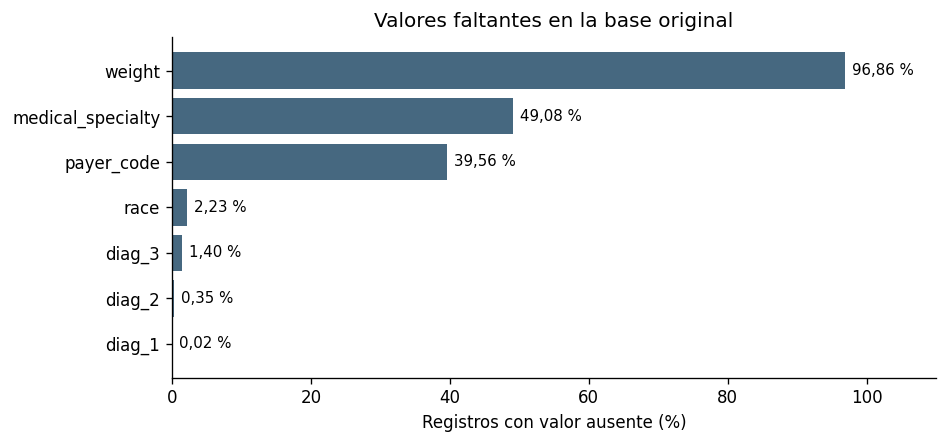

In [9]:
quality = pd.DataFrame({'nulos': raw.isna().sum(),
                        'porcentaje': raw.isna().mean().mul(100)}).sort_values('nulos', ascending=False)
quality = quality.loc[quality.nulos > 0]
mostrar(quality, 2)
quality.to_csv(OUT/'faltantes.csv')
fig, ax = plt.subplots(figsize=(8, 3.8))
q = quality.porcentaje.sort_values()
ax.barh(q.index, q.values, color='#466880')
for i, valor in enumerate(q):
    ax.text(valor+1, i, f'{es_num(valor,2)} %', va='center', fontsize=9)
ax.set(xlim=(0,110), xlabel='Registros con valor ausente (%)',
       title='Valores faltantes en la base original')
fig.tight_layout(); fig.savefig(OUT/'faltantes.png', dpi=160); plt.show()

In [10]:
display(Markdown(
    f"**Interpretación.** El peso está ausente en el **{es_num(quality.loc['weight','porcentaje'],2)} %** "
    f"de los registros; se propone excluirlo del modelo principal. La especialidad médica presenta "
    f"**{es_num(quality.loc['medical_specialty','porcentaje'],2)} %** de ausencia, y el pagador "
    f"**{es_num(quality.loc['payer_code','porcentaje'],2)} %**. La propuesta conserva una categoría "
    "explícita de ausencia en especialidad y excluye inicialmente el pagador. Los mecanismos "
    "que producen estos faltantes no pueden establecerse solo con los porcentajes observados."))

**Interpretación.** El peso está ausente en el **96,86 %** de los registros; se propone excluirlo del modelo principal. La especialidad médica presenta **49,08 %** de ausencia, y el pagador **39,56 %**. La propuesta conserva una categoría explícita de ausencia en especialidad y excluye inicialmente el pagador. Los mecanismos que producen estos faltantes no pueden establecerse solo con los porcentajes observados.

### 4.2 Registros repetidos, categorías especiales y constantes

Los duplicados exactos y los identificadores de encuentro repetidos se revisan por separado. Varias hospitalizaciones de una misma persona son registros distintos y deben mantenerse vinculadas al paciente durante la evaluación.

In [11]:
counts_patient = raw.patient_nbr.value_counts()
constants = raw.columns[raw.nunique(dropna=False) == 1].tolist()
controles = pd.Series({
    'Filas exactamente duplicadas': int(raw.duplicated().sum()),
    'encounter_id repetidos': int(raw.encounter_id.duplicated().sum()),
    'Pacientes con varias hospitalizaciones': int((counts_patient > 1).sum()),
    'Registros adicionales al primero de cada paciente': len(raw)-raw.patient_nbr.nunique(),
    'Máximo de hospitalizaciones por paciente': int(counts_patient.max()),
    'Registros con género Unknown/Invalid': int(raw.gender.eq('Unknown/Invalid').sum())
}, name='cantidad').to_frame()
mostrar(controles)
mostrar(pd.DataFrame({'variable_constante': constants,
                      'valor': [raw[c].iloc[0] for c in constants]}))
for variable in ['A1Cresult','max_glu_serum']:
    display(Markdown(f'**Categorías de {variable}**'))
    mostrar(raw[variable].value_counts(dropna=False).rename('registros').to_frame())

,cantidad
Filas exactamente duplicadas,0
encounter_id repetidos,0
Pacientes con varias hospitalizaciones,16773
Registros adicionales al primero de cada paciente,30248
Máximo de hospitalizaciones por paciente,40
Registros con género Unknown/Invalid,3


,variable_constante,valor
0,examide,No
1,citoglipton,No


**Categorías de A1Cresult**

,registros
A1Cresult,
None,84748
>8,8216
Norm,4990
>7,3812


**Categorías de max_glu_serum**

,registros
max_glu_serum,
None,96420
Norm,2597
>200,1485
>300,1264


**Interpretación.** No se identifican filas exactamente duplicadas ni identificadores de encuentro repetidos. Sí existen hospitalizaciones distintas de una misma persona. No se eliminan como errores. En la fase posterior deberá definirse una evaluación que mantenga juntas las observaciones de cada paciente.

Las columnas constantes se registran como un hallazgo de calidad; este notebook conserva todas las columnas originales.

### 4.3 Ausencias expresadas mediante códigos

El segundo CSV contiene tres bloques de equivalencias. Se leen respetando su estructura y se buscan códigos como `NULL`, `Not Available`, `Not Mapped` y `Unknown/Invalid`. Estos valores no aparecen como nulos de pandas porque el archivo principal conserva sus códigos numéricos.

In [12]:
mapping_rows = list(csv.reader(io.StringIO((DATA/'IDS_mapping.csv').read_text())))
mappings = {}; current = None
for row in mapping_rows:
    if not row or not row[0].strip():
        continue
    if row[0] in ['admission_type_id','discharge_disposition_id','admission_source_id']:
        current = row[0]; mappings[current] = {}; continue
    if current:
        mappings[current][int(row[0])] = row[1].strip()
semantic_rows = []
for field, lookup in mappings.items():
    semantic = [k for k,v in lookup.items()
                if v.lower() in ['null','not available','not mapped','unknown/invalid']]
    unknown_codes = sorted(set(raw[field])-set(lookup))
    semantic_rows.append([field, ', '.join(map(str,semantic)),
                          int(raw[field].isin(semantic).sum()),
                          raw[field].isin(semantic).mean()*100, str(unknown_codes)])
semantic_table = pd.DataFrame(semantic_rows, columns=[
    'variable','codigos_sin_informacion','registros','porcentaje','sin_descripcion_en_diccionario'])
mostrar(semantic_table, 2)
semantic_table.to_csv(OUT/'ausencias_codificadas.csv', index=False)

,variable,codigos_sin_informacion,registros,porcentaje,sin_descripcion_en_diccionario
0,admission_type_id,"5, 6, 8",10396,10.22,[]
1,discharge_disposition_id,"18, 25, 26",4680,4.60,[]
2,admission_source_id,"9, 15, 17, 20, 21",7067,6.94,[]


**Decisión.** La futura preparación debe tratar las ausencias codificadas como categorías sin información y documentar por separado cualquier código sin descripción. No se suman los registros de esta tabla con los nulos de otras variables: una hospitalización puede tener problemas en varias columnas.

### 4.4 Observaciones extremas y consistencia de rangos

La regla exploratoria usa **RIC = Q3 − Q1** y marca valores inferiores a **Q1 − 1,5 × RIC** o superiores a **Q3 + 1,5 × RIC**. Se aplica a la base original. Un valor señalado no es necesariamente erróneo; no se elimina ni modifica.

Cuando el RIC es cero, cualquier valor positivo de una variable concentrada en cero puede quedar señalado. Los resultados describen el archivo y no fijan reglas definitivas de depuración para un modelo.

In [13]:
outlier_rows=[]
for c in numeric:
    q1,q3=raw[c].quantile([.25,.75]); iqr=q3-q1
    lower,upper=q1-1.5*iqr,q3+1.5*iqr
    flag=(raw[c]<lower)|(raw[c]>upper)
    outlier_rows.append([c,q1,q3,lower,upper,int(flag.sum()),flag.mean()*100])
outliers=pd.DataFrame(outlier_rows,columns=['variable','Q1','Q3','limite_inferior','limite_superior','n_senalados','porcentaje'])
print('\nExtremos según 1,5 RIC en la base original:')
mostrar(outliers, 2)
print('\nEstancias fuera del intervalo documentado de 1 a 14 días:', int((~raw.time_in_hospital.between(1,14)).sum()))
print('Conteos negativos:', int((raw[numeric]<0).sum().sum()))
outliers.to_csv(OUT/'extremos_base_original.csv', index=False)


Extremos según 1,5 RIC en la base original:

Estancias fuera del intervalo documentado de 1 a 14 días: 0
Conteos negativos: 0


,variable,Q1,Q3,limite_inferior,limite_superior,n_senalados,porcentaje
0,time_in_hospital,2.0,6.0,-4.0,12.0,2252,2.21
1,num_lab_procedures,31.0,57.0,-8.0,96.0,143,0.14
2,num_procedures,0.0,2.0,-3.0,5.0,4954,4.87
3,num_medications,10.0,20.0,-5.0,35.0,2557,2.51
4,number_outpatient,0.0,0.0,0.0,0.0,16739,16.45
5,number_emergency,0.0,0.0,0.0,0.0,11383,11.19
6,number_inpatient,0.0,1.0,-1.5,2.5,7049,6.93
7,number_diagnoses,6.0,9.0,1.5,13.5,281,0.28


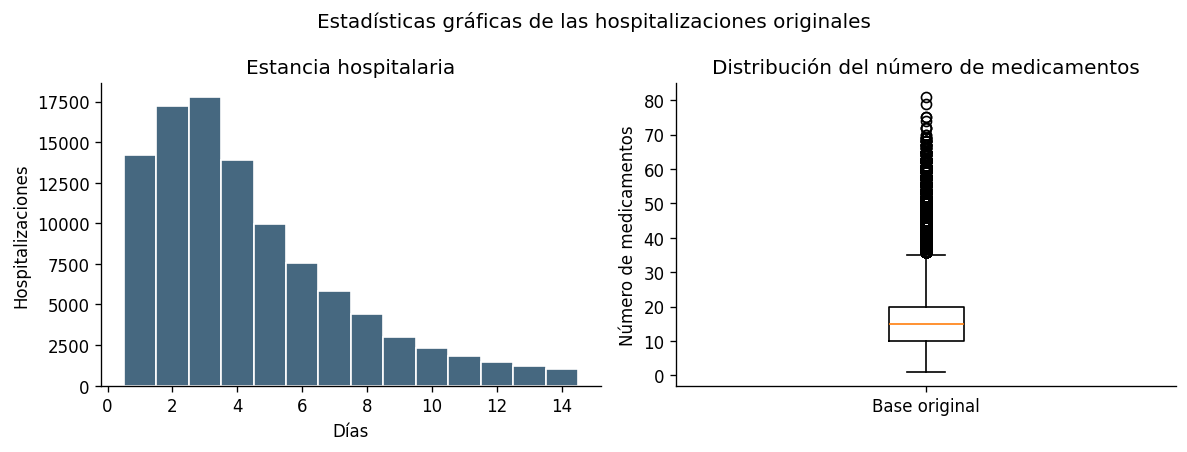

In [14]:
fig, axes = plt.subplots(1,2,figsize=(10,3.8))
axes[0].hist(raw.time_in_hospital, bins=np.arange(.5,15.5,1),
             color='#466880',edgecolor='white')
axes[0].set(title='Estancia hospitalaria',xlabel='Días',ylabel='Hospitalizaciones')
axes[1].boxplot(raw.num_medications, tick_labels=['Base original'])
axes[1].set(title='Distribución del número de medicamentos',ylabel='Número de medicamentos')
fig.suptitle('Estadísticas gráficas de las hospitalizaciones originales')
fig.tight_layout();fig.savefig(OUT/'distribuciones_originales.png',dpi=160);plt.show()

In [15]:
extremos_por_variable = outliers.set_index('variable')
display(Markdown(
    f"**Interpretación.** En la base original, la regla identifica "
    f"**{es_num(extremos_por_variable.loc['num_medications','n_senalados'])}** registros "
    "con más de 35 medicamentos y "
    f"**{es_num(extremos_por_variable.loc['time_in_hospital','n_senalados'])}** "
    "con estancias superiores a 12 días. Los límites de 1 a 14 días corresponden a la selección "
    "del dataset. En consultas ambulatorias y urgencias previas, el RIC cero limita la utilidad "
    "de esta regla; todos los casos se conservan para su evaluación posterior."))

**Interpretación.** En la base original, la regla identifica **2.557** registros con más de 35 medicamentos y **2.252** con estancias superiores a 12 días. Los límites de 1 a 14 días corresponden a la selección del dataset. En consultas ambulatorias y urgencias previas, el RIC cero limita la utilidad de esta regla; todos los casos se conservan para su evaluación posterior.

## 5 Distribución de la variable objetivo

Se conservan las tres categorías originales de `readmitted`:

| Categoría | Significado en el archivo |
|---|---|
| `NO` | No consta un reingreso en la fuente. |
| `>30` | Reingreso registrado en más de 30 días. |
| `<30` | Reingreso registrado en menos de 30 días. |

Aunque el título académico dice «a 30 días», la etiqueta positiva disponible es literalmente `<30`. Sin fechas exactas no se puede redefinir la clasificación del día 30. La categoría `NO` tampoco demuestra ausencia de atención fuera de la fuente.

Positivos: 11357 | negativos: 90409
Razón negativos/positivos: 7.96
Exactitud de predecir siempre negativo: 88.84 %


,n,porcentaje
readmitted,,
NO,54864,53.912
>30,35545,34.928
<30,11357,11.160


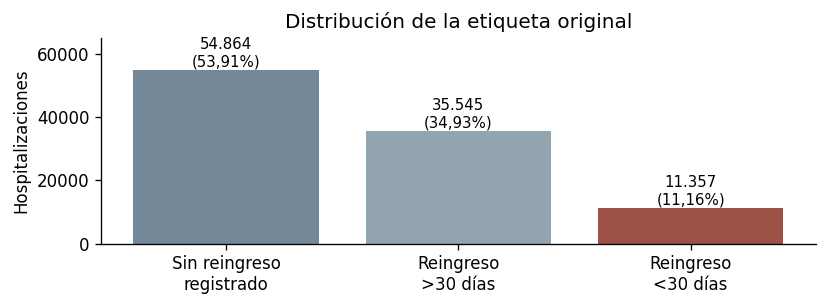

In [16]:
target_original = raw.readmitted.value_counts().reindex(['NO', '>30', '<30'])
target_table = pd.DataFrame({'n': target_original, 'porcentaje': target_original/len(raw)*100})
mostrar(target_table, 3)
y_raw = raw.readmitted.eq('<30').astype('int8')
print('Positivos:', int(y_raw.sum()), '| negativos:', int((y_raw==0).sum()))
print('Razón negativos/positivos:', round((y_raw==0).sum()/y_raw.sum(), 2))
print('Exactitud de predecir siempre negativo:', round(100*(1-y_raw.mean()), 3), '%')
fig, ax = plt.subplots(figsize=(7, 2.65))
bars=ax.bar(['Sin reingreso\nregistrado', 'Reingreso\n>30 días', 'Reingreso\n<30 días'], target_original.values,
           color=['#738899','#92a4b0','#9e5147'])
for b, n in zip(bars, target_original):
    ax.text(b.get_x()+b.get_width()/2, n+1100, f'{n:,}\n({n/len(raw)*100:.2f}%)'.replace(',','X').replace('.',',').replace('X','.'), ha='center', fontsize=9)
ax.set(ylim=(0,65000), ylabel='Hospitalizaciones', title='Distribución de la etiqueta original')
fig.tight_layout(); fig.savefig(OUT/'clases.png', dpi=180); plt.show()
target_table.to_csv(OUT/'distribucion_objetivo_original.csv')

In [17]:
display(Markdown(
    f"**Interpretación del desbalance.** Los **{es_num(target_original['<30'])}** reingresos "
    f"tempranos representan **{es_num(100*target_original['<30']/len(raw),2)} %** del archivo. "
    f"Al reunir `NO` y `>30`, se obtiene una razón aproximada de "
    f"**{es_num((target_original['NO']+target_original['>30'])/target_original['<30'],2)} "
    "registros negativos por positivo**. Predecir siempre ausencia de reingreso temprano daría "
    f"{es_num(100*(1-y_raw.mean()),2)} % de exactitud y sensibilidad cero. Este cálculo "
    "describe un escenario constante de referencia, no el rendimiento de un modelo entrenado."))

**Interpretación del desbalance.** Los **11.357** reingresos tempranos representan **11,16 %** del archivo. Al reunir `NO` y `>30`, se obtiene una razón aproximada de **7,96 registros negativos por positivo**. Predecir siempre ausencia de reingreso temprano daría 88,84 % de exactitud y sensibilidad cero. Este cálculo describe un escenario constante de referencia, no el rendimiento de un modelo entrenado.

**Alcance y límites.** La exploración conserva las 101.766 hospitalizaciones originales y sus 50 columnas. No se ha construido una cohorte depurada ni se han asignado conjuntos de entrenamiento, validación o prueba. Estos pasos corresponden a la preparación posterior y deberán documentarse antes de ajustar transformaciones o seleccionar modelos.

Los datos son históricos y proceden de Estados Unidos. No permiten establecer con certeza si un reingreso fue programado o evitable. Las frecuencias observadas no constituyen recomendaciones clínicas ni resultados validados para hospitales colombianos.

**Trazabilidad de la ejecución.** El siguiente registro conserva las dimensiones, las huellas de los archivos, las versiones de las bibliotecas y los resultados principales. Las tablas y figuras exportadas permiten revisar el análisis sin modificar los CSV originales.

In [18]:
assert raw.shape == (101766,50), 'El análisis debe conservar el archivo original.'
resumen = {
 'ejecutado_utc':ejecutado_utc, 'fuente_url':URL, 'sha256':huellas,
 'filas':len(raw), 'columnas':raw.shape[1], 'pacientes':int(raw.patient_nbr.nunique()),
 'clases_originales':{k:int(v) for k,v in target_original.items()},
 'faltantes':quality.to_dict(orient='index'), 'constantes':constants,
 'duplicados_exactos':int(raw.duplicated().sum()),
 'encuentros_repetidos':int(raw.encounter_id.duplicated().sum()),
 'extremos_base_original':outliers.to_dict(orient='records'),
 'versiones':{'python':platform.python_version(),'pandas':pd.__version__,
              'numpy':np.__version__,'matplotlib':__import__('matplotlib').__version__}
}
(OUT/'resumen_eda_fase1.json').write_text(
    json.dumps(resumen,ensure_ascii=False,indent=2),encoding='utf-8')
print('Exploración finalizada. Los registros y columnas originales se conservan.')
mostrar(pd.DataFrame({'archivo_generado':sorted(f.name for f in OUT.iterdir() if f.is_file())}))

Exploración finalizada. Los registros y columnas originales se conservan.


,archivo_generado
0,ausencias_codificadas.csv
1,clases.png
2,descriptivos_base_original.csv
3,diccionario_variables.csv
4,distribucion_objetivo_original.csv
5,distribuciones_originales.png
6,extremos_base_original.csv
7,faltantes.csv
8,faltantes.png
9,resumen_eda_fase1.json


**Referencias**

- Clore, J., Cios, K., DeShazo, J. y Strack, B. (2014). *Diabetes 130-US Hospitals for Years 1999–2008* [Conjunto de datos]. UCI. https://doi.org/10.24432/C5230J
- Strack, B. et al. (2014). *Impact of HbA1c Measurement on Hospital Readmission Rates: Analysis of 70,000 Clinical Database Patient Records*. BioMed Research International, 2014, 781670. https://doi.org/10.1155/2014/781670
- pandas developers. *pandas.read_csv*. https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html
- pandas developers. *pandas.Series.nunique* y *pandas.Series.dropna*. https://pandas.pydata.org/docs/reference/api/pandas.Series.nunique.html y https://pandas.pydata.org/docs/reference/api/pandas.Series.dropna.html

Los datos se atribuyen a sus autores y a UCI conforme a la licencia CC BY 4.0. Los resultados se generan mediante las celdas del notebook.